# 11: Other paths: energetic deuterons in metals, ignition, and low-waste options

The question: are there paths not yet considered that close the gap, reach ignition, or sustain fission **without long-lived harmful waste**? Notebooks 01–10 closed fusion *at rest*. This notebook covers the remaining families:

1. **Energetic deuterons inside metals** (computed here). This is the family behind NASA's "lattice confinement fusion" (2020: bremsstrahlung photons make energetic deuterons inside ErD₃/TiD₂) and beam-loaded PdD (Karahadian et al. 2026, screening up to 1.7 keV). Can any of it return more energy than it costs?
2. **Catalysis by heavy negative particles** (muons done in 09–10; hypothetical stable ones).
3. **Hot fusion and ignition status**, including aneutronic fuels (D–³He, p–¹¹B).
4. **Low-waste fission** (partitioning and transmutation, accelerator-driven systems, thorium molten salt).

Sources were gathered with `tools/fetch.py` and web search; status levels as in VERIFICATION.md.

## 1. Energetic deuterons in a metal: the best possible energy return

A deuteron of energy E₀ entering deuterated metal slows down, mainly by giving energy to electrons. Along the way it may fuse with a lattice deuteron. The fusion probability over its whole path is

$$P(E_0) = \int_0^{E_0} \frac{n_D\,\sigma(E)}{|dE/dx|}\,dE,$$

and the energy return is G = P·⟨Q⟩/E₀ (⟨Q⟩ = 3.65 MeV, both d+d branches). σ uses the Bosch–Hale S-factors, with the screening shift E → E + U_e. Stopping uses Bethe at high energy combined with a velocity-proportional low-energy term (a hand-calibrated approximation for Pd, I = 470 eV, peak ≈ 25 eV per 10¹⁵ atoms/cm²; uncertain to a factor ~2, varied ×0.5–×2). An optimistic bound replaces Pd with pure deuterium, where the only stopping is from deuterium's own electrons.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import integrate
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#0b0b0b","#52514e"
BG = 31.3970
SF = {"n": [5.3701e4, 3.3027e2, -1.2706e-1, 2.9327e-5, -2.5151e-9],
      "p": [5.5576e4, 2.1054e2, -3.2638e-2, 1.4987e-6, 1.8181e-10]}
def S_keVb(E): return sum(A[0] + E*(A[1] + E*(A[2] + E*(A[3] + E*A[4]))) for A in SF.values())*1e-3
def sigma(Ecm, U=0.0): return S_keVb(Ecm)/Ecm*np.exp(-BG/np.sqrt(Ecm + U))*1e-24     # cm^2
E4 = (1.44e-7)**2
def stopping(E_keV, target="PdD", scale=1.0):
    # eV per cm, deuteron of lab energy E_keV
    mv2 = 2*E_keV*1e3/3670.48
    if target == "PdD":
        n_atoms, Z2, I, a = 6.8e22, 46, 470.0, 4.0
    else:                                    # pure deuterium (solid D2 density), deuterium's own electrons only
        n_atoms, Z2, I, a = 6.1e22, 1, 19.0, 4.0/46*1.6
    SB = 4*np.pi*E4*Z2/mv2*np.log(1 + 2*mv2/I)
    SL = a*np.sqrt(E_keV)*1e-15*Z2/46*46/Z2 if target == "PdD" else a*np.sqrt(E_keV)*1e-15
    return scale*n_atoms/(1/SL + 1/SB)
n_D = 6.1e22
def gain(E0_keV, U_eV=0.0, target="PdD", scale=1.0):
    f = lambda E: 1e3*n_D*sigma(E/2, U_eV/1e3)/stopping(E, target, scale)     # dE in keV, stopping in eV/cm
    P, _ = integrate.quad(f, 0.5, E0_keV, limit=400)
    return P, P*3650.0/E0_keV
for E0 in [5, 20, 100, 1000, 3000]:
    P, G = gain(E0)
    print(f"E0 = {E0:5d} keV (PdD, no screening): fusion probability {P:.1e}, energy return G = {G:.1e}")

E0 =     5 keV (PdD, no screening): fusion probability 6.2e-15, energy return G = 4.5e-12
E0 =    20 keV (PdD, no screening): fusion probability 1.5e-10, energy return G = 2.7e-08
E0 =   100 keV (PdD, no screening): fusion probability 5.3e-08, energy return G = 1.9e-06
E0 =  1000 keV (PdD, no screening): fusion probability 4.3e-06, energy return G = 1.6e-05
E0 =  3000 keV (PdD, no screening): fusion probability 2.4e-05, energy return G = 2.9e-05


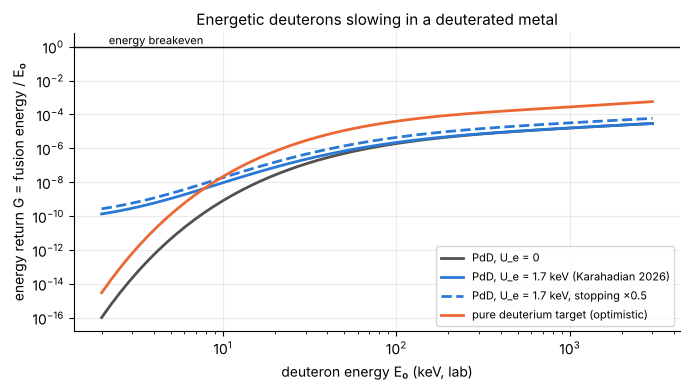

PdD                         : best G = 2.9e-05 at E0 = 3000 keV   ->  4.5 orders below breakeven
PdD 1.7 keV                 : best G = 2.9e-05 at E0 = 3000 keV   ->  4.5 orders below breakeven
PdD 1.7 keV, stopping x0.5  : best G = 5.9e-05 at E0 = 3000 keV   ->  4.2 orders below breakeven
pure D                      : best G = 5.7e-04 at E0 = 3000 keV   ->  3.2 orders below breakeven

screening 0 -> 1.7 keV raises G at 5 keV by x241, but G at 5 keV is only 1.1e-09


In [2]:
E0s = np.logspace(np.log10(2), np.log10(3000), 60)
fig, ax = plt.subplots(figsize=(7, 4))
for (lab, kw, col, ls) in [("PdD, U_e = 0", dict(), MUTED, "-"),
                            ("PdD, U_e = 1.7 keV (Karahadian 2026)", dict(U_eV=1700), BLUE, "-"),
                            ("PdD, U_e = 1.7 keV, stopping ×0.5", dict(U_eV=1700, scale=0.5), BLUE, "--"),
                            ("pure deuterium target (optimistic)", dict(target="D"), ORANGE, "-")]:
    ax.loglog(E0s, [gain(E, **kw)[1] for E in E0s], color=col, ls=ls, lw=2, label=lab)
ax.axhline(1, color=INK, lw=1); ax.text(2.2, 1.4, "energy breakeven", fontsize=8)
ax.set_xlabel("deuteron energy E₀ (keV, lab)"); ax.set_ylabel("energy return G = fusion energy / E₀")
ax.set_title("Energetic deuterons slowing in a deuterated metal"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("../figures/11_beam_in_metal.png", dpi=130); plt.show()
best = {}
for lab, kw in [("PdD", {}), ("PdD 1.7 keV", dict(U_eV=1700)), ("PdD 1.7 keV, stopping x0.5", dict(U_eV=1700, scale=0.5)), ("pure D", dict(target="D"))]:
    Gs = np.array([gain(E, **kw)[1] for E in E0s]); i = Gs.argmax()
    best[lab] = Gs[i]
    print(f"{lab:28s}: best G = {Gs[i]:.1e} at E0 = {E0s[i]:.0f} keV   ->  {np.log10(1/Gs[i]):.1f} orders below breakeven")
print(f"\nscreening 0 -> 1.7 keV raises G at 5 keV by x{gain(5, U_eV=1700)[1]/gain(5)[1]:.0f}, but G at 5 keV is only {gain(5, U_eV=1700)[1]:.1e}")

**Result:** the energy returned by an energetic deuteron in deuterated metal is at most **G ≈ 3×10⁻⁵** (PdD, MeV energies; 6×10⁻⁵ with stopping halved), **~4.5 orders of magnitude below breakeven**. Even an optimistic pure-deuterium target reaches only ~6×10⁻⁴ (3.2 orders short). That's before counting the cost of making the deuteron energetic (accelerator or bremsstrahlung efficiency of ≲10–50%). G still rises slowly towards 3 MeV (the top of the computed range), but the d+d cross-section saturates at ~0.1–0.2 b, so it cannot rise by orders of magnitude. Screening, even at the reported 1.7 keV, multiplies the yield ×240 at 5 keV, where G is only ~10⁻⁹, and leaves the best case unchanged. It can't help, because a deuteron is far more likely to lose its energy to electrons than to fuse. **Lattice confinement fusion and beam-loaded metals are therefore neutron sources and screening laboratories, not energy sources.** The only way around electronic stopping is to keep the fuel hot so the energy is recycled. That is thermonuclear fusion (section 3).

## 2. Catalysis by heavy negative particles

| Catalyst | Status | Gap |
|---|---|---|
| Muon (μ⁻) | Works; ~150 fusions per muon (notebook 09) | ~9× from net electricity (pure); hybrid needs fission (notebook 10) |
| Pion/kaon | Lifetimes 26 ns / 12 ns, too short for many cycles | No route |
| Hypothetical **long-lived heavy negative particle** | Would catalyse fusion without decay losses (only sticking ends a cycle); none has been found in searches for exotic heavy isotopes | Would be revolutionary; no evidence |

Muons remain the one physical catalyst. Their roadmap is in notebook 10 and the muon note.

## 3. Hot fusion and ignition status (sources: web search, status secondary/abstract unless noted)

| Path | Status (2025–26) | What's missing |
|---|---|---|
| **Laser ICF, d–t (NIF)** | Ignition repeated; record **8.6 MJ from 2.08 MJ laser, target gain ≈ 4.1** (2025) | LLNL estimates target gain ~15 for a facility with zero net electric demand; laser wall-plug efficiency and repetition rate for a plant |
| **D–³He (Helion, field-reversed)** | Polaris reported measurable d–t fusion and 150 million °C (Feb 2026); D–³He needs ~200 million °C; ³He to be bred from d–d | D–³He plasma not yet reported; ³He supply unproven at scale |
| **p–¹¹B, thermal plasma** | With modern cross-sections, fusion power exceeds bremsstrahlung by only a few % at best (Putvinski et al.); alpha channeling could cut the required confinement ×2.6–6.9; <2% ash prevents ignition | Marginal power balance; ash removal |
| **p–¹¹B, inertial** | Breakeven needs ~100× current areal density at ~1000× pressure, and trapped bremsstrahlung (Ochs et al., Phys. Plasmas 2026) | Far from current capability |
| **p–¹¹B, laser-driven non-thermal** | ~10¹¹ alphas per 600 J pulse (PALS 2020), i.e. ~2×10⁸ alphas per joule, fusion energy ≈ 8×10⁻⁵ of laser energy (computed below) | ~4 orders from breakeven |
| **p–¹¹B, dense plasma focus (LPPFusion)** | >200 keV ion energies (deuterium); decaborane runs began 2025 | No p–¹¹B yield published |

In [3]:
alphas_per_J = 1e11/600; E_alpha_J = 8.7e6*1.602e-19/3       # 8.7 MeV per p-B11 reaction shared by 3 alphas
print(f"laser-driven p-B11 (PALS 2020): {alphas_per_J:.1e} alphas/J -> fusion energy / laser energy = {alphas_per_J*E_alpha_J:.1e}")
print(f"NIF 2025: target gain {8.6/2.08:.2f}; facility zero-net needs ~15 -> x{15/(8.6/2.08):.1f} still needed")

laser-driven p-B11 (PALS 2020): 1.7e+08 alphas/J -> fusion energy / laser energy = 7.7e-05
NIF 2025: target gain 4.13; facility zero-net needs ~15 -> x3.6 still needed


## 4. Waste: what "no harmful deposits" can and can't mean

| Option | Long-term waste | Status |
|---|---|---|
| Today's fission (once-through) | Spent fuel stays more radiotoxic than the original uranium ore for **~300,000 years** | Operating |
| Fission with recycled plutonium | Minor actinides keep it above ore level for **~10,000 years** | Operating (France) |
| **Partitioning and transmutation** (fast reactors or accelerator-driven systems) | Radiotoxicity below natural-uranium level after **~300 years** | MYRRHA (Belgium) ADS: first 100 MeV phase slipped to 2027–2038; reported as possibly frozen (unconfirmed) |
| **Thorium molten salt** | Far fewer transuranics; fission products still made | TMSR-LF1 (China): critical 2023, thorium→uranium conversion achieved 2025; larger units targeted ~2030. No published radiotoxicity data found |
| d–t fusion | No fission products or actinides; activated structure. EU DEMO studies: ~10⁴ t intermediate-level waste 100 years after shutdown, mainly ¹⁴C in steels | Design studies |
| D–³He / p–¹¹B fusion | Few (D–³He) or almost no (p–¹¹B) neutrons, so little activation | Not yet demonstrated |

**Honest summary:** fission always makes fission products; the best demonstrated-in-principle route (partitioning and transmutation) shortens the hazard from ~300,000 to ~300 years but doesn't eliminate it. Truly "deposit-free" energy among nuclear options means **aneutronic fusion**, which is the furthest from working.

## 5. Verdict: is there a path we hadn't considered?

* **Energetic deuterons inside metals** (lattice confinement fusion, beam-loaded PdD): computed here, **~4.5 orders below energy breakeven** (3.2 for an idealised pure-deuterium target), and screening can't change that. Not an energy path.
* **Catalysis:** muons are the only real catalyst. Their gap (~9×) is engineering, not physics.
* **Hot fusion:** ignition is real (NIF gain ~4); the remaining gap to a power plant is ~4× in target gain plus driver efficiency, i.e. **under one order of magnitude**, in contrast with 15–114 orders for fusion at rest.
* **Low waste:** d–t fusion leaves activated structure (decades to centuries, ¹⁴C-limited); p–¹¹B would be cleanest but is marginal in power balance; fission's best case is ~300-year waste with transmutation.

**Bottom line:** no unconsidered room-temperature path closes the gap within known physics. The paths with gaps of order 10× or less are **hot fusion (laser and magnetic)** and **muon catalysis**, and the cleanest long-term fuel is **p–¹¹B**, whose obstacle is radiation loss, not orders of magnitude in tunnelling.